In [49]:
!nvidia-smi

Sun Nov 15 13:11:02 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 610.57.01              KMD Version: 610.88        CUDA UMD Version: 13.3     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 4080        On  |   00000000:01:00.0  On |                  N/A |
| 31%   39C    P8             12W /  320W |    1023MiB /  16376MiB |      5%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [50]:
from numba import cuda, float64, int64
from numba.cuda.random import create_xoroshiro128p_states
from numba.cuda.random import xoroshiro128p_normal_float32
from numba.cuda.random import xoroshiro128p_uniform_float32

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import math
import time

In [51]:
L = 64
N = L * L
J = 1.0

q0 = np.pi / 4
D = np.sqrt(2) * np.tan(q0)
J2 = J / (4 * np.cos(q0))

B_z = 0.0

replicas = 32
adapt_every = 500
sample_every = 1000

seed_dmi = 2026
seed_frustration = 2027

n_therm = 500000
n_measure = 1000000

sigma_initial = 0.6
T = np.linspace(3, 0.1, 100)

In [52]:

def random_spin_field():
    spins = np.random.normal(size=(L, L, 3))
    spins /= np.linalg.norm(spins, axis=2, keepdims=True)
    return spins

lattice = random_spin_field()

print(lattice.shape)


(64, 64, 3)


In [53]:

def delta_energy_dmi(lattice, x, y, trial_spin, B_z):
    L = lattice.shape[0]

    nn = (
        lattice[(x + 1) % L, y]
        + lattice[(x - 1) % L, y]
        + lattice[x, (y + 1) % L]
        + lattice[x, (y - 1) % L]
    )

    old_spin = lattice[x, y]
    delta_spin = trial_spin - old_spin

    E_exchange = -J * np.dot(delta_spin, nn)

    E_dmi = -D * (
        np.dot(
            delta_spin,
            np.cross(
                lattice[(x + 1) % L, y] - lattice[(x - 1) % L, y],
                [1, 0, 0]
            )
        )
        + np.dot(
            delta_spin,
            np.cross(
                lattice[x, (y + 1) % L] - lattice[x, (y - 1) % L],
                [0, 1, 0]
            )
        )
    )

    E_field = -B_z * delta_spin[2]

    return E_exchange + E_dmi + E_field


def delta_energy_frustration(lattice, x, y, trial_spin, B_z):
    L = lattice.shape[0]

    nn = (
        lattice[(x + 1) % L, y]
        + lattice[(x - 1) % L, y]
        + lattice[x, (y + 1) % L]
        + lattice[x, (y - 1) % L]
    )

    nnn = (
        lattice[(x + 2) % L, y]
        + lattice[(x - 2) % L, y]
    )

    old_spin = lattice[x, y]
    delta_spin = trial_spin - old_spin

    E_exchange = -J * np.dot(delta_spin, nn)
    E_frustration = J2 * np.dot(delta_spin, nnn)
    E_field = -B_z * delta_spin[2]

    return E_exchange + E_frustration + E_field


In [54]:

def total_energy_dmi(lattice, B_z):
    nx, ny = lattice.shape[:2]
    E = 0.0

    for x in range(nx):
        for y in range(ny):
            E += -J * np.dot(
                lattice[x, y],
                lattice[(x + 1) % nx, y] + lattice[x, (y + 1) % ny]
            )

            E += D * (
                np.dot(
                    lattice[x, y],
                    np.cross([1, 0, 0], lattice[(x + 1) % nx, y])
                )
                + np.dot(
                    lattice[x, y],
                    np.cross([0, 1, 0], lattice[x, (y + 1) % ny])
                )
            )

            E -= B_z * lattice[x, y, 2]

    return E


def total_energy_frustration(lattice, B_z):
    nx, ny = lattice.shape[:2]
    E = 0.0

    for x in range(nx):
        for y in range(ny):
            nn = lattice[(x + 1) % nx, y] + lattice[x, (y + 1) % ny]
            nnn = lattice[(x + 2) % nx, y]

            E += -J * np.dot(lattice[x, y], nn)
            E += J2 * np.dot(lattice[x, y], nnn)
            E -= B_z * lattice[x, y, 2]

    return E


In [55]:

@cuda.jit
def gpu_sweeps(spins, counts, rng_states, temp, d_sigma, B_z, model_id, J, J2, D, sweeps):

    replica = cuda.blockIdx.x
    tid = cuda.threadIdx.x

    nx = spins.shape[1]
    ny = spins.shape[2]

    n_per_color = (nx // 4) * (ny // 2)
    rid = replica * n_per_color + tid

    sigma = d_sigma[0]
    accepted = 0

    for sweep in range(sweeps):
        for color in range(8):

            cx = color // 2
            cy = color % 2

            x = 4 * (tid // (ny // 2)) + cx
            y = 2 * (tid % (ny // 2)) + cy

            xp = (x + 1) % nx
            xm = (x - 1) % nx
            yp = (y + 1) % ny
            ym = (y - 1) % ny

            old_x = spins[replica, x, y, 0]
            old_y = spins[replica, x, y, 1]
            old_z = spins[replica, x, y, 2]

            # Gaussian trial
            tx = old_x + sigma * xoroshiro128p_normal_float32(rng_states, rid)
            ty = old_y + sigma * xoroshiro128p_normal_float32(rng_states, rid)
            tz = old_z + sigma * xoroshiro128p_normal_float32(rng_states, rid)

            norm = math.sqrt(tx*tx + ty*ty + tz*tz)

            if norm > 0.0:
                tx /= norm
                ty /= norm
                tz /= norm

                dx = tx - old_x
                dy = ty - old_y
                dz = tz - old_z

                # Nearest-neighbor exchange
                n0 = (
                    spins[replica, xp, y, 0]
                    + spins[replica, xm, y, 0]
                    + spins[replica, x, yp, 0]
                    + spins[replica, x, ym, 0]
                )

                n1 = (
                    spins[replica, xp, y, 1]
                    + spins[replica, xm, y, 1]
                    + spins[replica, x, yp, 1]
                    + spins[replica, x, ym, 1]
                )

                n2 = (
                    spins[replica, xp, y, 2]
                    + spins[replica, xm, y, 2]
                    + spins[replica, x, yp, 2]
                    + spins[replica, x, ym, 2]
                )

                dE = -J * (dx*n0 + dy*n1 + dz*n2) - B_z*dz

                if model_id == 1:
                    xpp = (x + 2) % nx
                    xmm = (x - 2) % nx

                    dE += J2 * (
                        dx * (
                            spins[replica, xpp, y, 0]
                            + spins[replica, xmm, y, 0]
                        )
                        + dy * (
                            spins[replica, xpp, y, 1]
                            + spins[replica, xmm, y, 1]
                        )
                        + dz * (
                            spins[replica, xpp, y, 2]
                            + spins[replica, xmm, y, 2]
                        )
                    )

                else:
                    # Dzyaloshinskii-Moriya interaction
                    ax1 = (
                        spins[replica, xp, y, 2]
                        - spins[replica, xm, y, 2]
                    )

                    ax2 = -(
                        spins[replica, xp, y, 1]
                        - spins[replica, xm, y, 1]
                    )

                    ay0 = -(
                        spins[replica, x, yp, 2]
                        - spins[replica, x, ym, 2]
                    )

                    ay2 = (
                        spins[replica, x, yp, 0]
                        - spins[replica, x, ym, 0]
                    )

                    dE -= D * (
                        dx*ay0 + dy*ax1 + dz*(ax2 + ay2)
                    )

                # Metropolis acceptance
                if dE <= 0.0 or (
                    temp > 0.0 and
                    xoroshiro128p_uniform_float32(rng_states, rid) < math.exp(-dE/temp)
                ):
                    spins[replica, x, y, 0] = tx
                    spins[replica, x, y, 1] = ty
                    spins[replica, x, y, 2] = tz
                    accepted += 1

            cuda.syncthreads()

    counts[replica, tid] = accepted


In [56]:

@cuda.jit
def measure_gpu(spins, energies, magnetizations, B_z, model_id, J, J2, D):

    r = cuda.blockIdx.x
    tid = cuda.threadIdx.x

    nx = spins.shape[1]
    ny = spins.shape[2]

    sh_e = cuda.shared.array(256, dtype=float64)
    sh_mx = cuda.shared.array(256, dtype=float64)
    sh_my = cuda.shared.array(256, dtype=float64)
    sh_mz = cuda.shared.array(256, dtype=float64)

    e = 0.0
    mx = 0.0
    my = 0.0
    mz = 0.0

    for k in range(tid, nx * ny, cuda.blockDim.x):
        x = k // ny
        y = k % ny

        xp = (x + 1) % nx
        yp = (y + 1) % ny

        sx = float64(spins[r, x, y, 0])
        sy = float64(spins[r, x, y, 1])
        sz = float64(spins[r, x, y, 2])

        ax = float64(spins[r, xp, y, 0])
        ay = float64(spins[r, xp, y, 1])
        az = float64(spins[r, xp, y, 2])

        bx = float64(spins[r, x, yp, 0])
        by = float64(spins[r, x, yp, 1])
        bz = float64(spins[r, x, yp, 2])

        e -= J * (
            sx * (ax + bx)
            + sy * (ay + by)
            + sz * (az + bz)
        )

        e -= B_z * sz

        if model_id == 1:
            xpp = (x + 2) % nx

            e += J2 * (
                sx * float64(spins[r, xpp, y, 0])
                + sy * float64(spins[r, xpp, y, 1])
                + sz * float64(spins[r, xpp, y, 2])
            )

        else:
            e -= D * (
                sy * az - sz * ay
                + sz * bx - sx * bz
            )

        mx += sx
        my += sy
        mz += sz

    sh_e[tid] = e
    sh_mx[tid] = mx
    sh_my[tid] = my
    sh_mz[tid] = mz

    cuda.syncthreads()

    stride = cuda.blockDim.x // 2

    while stride > 0:
        if tid < stride:
            sh_e[tid] += sh_e[tid + stride]
            sh_mx[tid] += sh_mx[tid + stride]
            sh_my[tid] += sh_my[tid + stride]
            sh_mz[tid] += sh_mz[tid + stride]

        cuda.syncthreads()
        stride //= 2

    if tid == 0:
        energies[r] = sh_e[0]
        magnetizations[r, 0] = sh_mx[0]
        magnetizations[r, 1] = sh_my[0]
        magnetizations[r, 2] = sh_mz[0]


In [57]:

@cuda.jit
def adapt_sigma_gpu(counts, d_sigma, N, sweeps):

    tid = cuda.threadIdx.x
    ncols = counts.shape[1]
    total = 0

    for i in range(tid, counts.shape[0] * ncols, 256):
        total += counts[i // ncols, i % ncols]

    sh = cuda.shared.array(256, dtype=int64)
    sh[tid] = total

    cuda.syncthreads()

    stride = 128

    while stride > 0:
        if tid < stride:
            sh[tid] += sh[tid + stride]

        cuda.syncthreads()
        stride //= 2

    if tid == 0:
        R = sh[0] / (counts.shape[0] * N * sweeps)
        sigma = d_sigma[0] * math.exp(0.5 * (R - 0.5))
        d_sigma[0] = min(max(sigma, 1e-3), 2.0)


In [58]:

@cuda.jit
def accumulate_stats_gpu(d_energies, d_magnetizations, counts, stats):

    r = cuda.grid(1)

    if r < d_energies.shape[0]:
        n = stats[r, 0] + 1.0

        E = d_energies[r]

        delta_E = E - stats[r, 1]
        E_mean = stats[r, 1] + delta_E / n

        stats[r, 2] += delta_E * (E - E_mean)
        stats[r, 1] = E_mean

        mx = d_magnetizations[r, 0]
        my = d_magnetizations[r, 1]
        mz = d_magnetizations[r, 2]

        M_abs = math.sqrt(mx*mx + my*my + mz*mz)

        delta_M = M_abs - stats[r, 3]
        M_abs_mean = stats[r, 3] + delta_M / n

        stats[r, 4] += delta_M * (M_abs - M_abs_mean)
        stats[r, 3] = M_abs_mean
        stats[r, 0] = n

        accepted = 0

        for k in range(counts.shape[1]):
            accepted += counts[r, k]

        stats[r, 5] += accepted


In [59]:

@cuda.jit
def finalize_stats_gpu(stats, d_sigma, result, temp, N, n_measure):

    if cuda.grid(1) == 0:
        n_total = 0.0

        E_mean = 0.0
        E_m2 = 0.0

        M_abs_mean = 0.0
        M_m2 = 0.0

        accepted_sum = 0.0

        for r in range(stats.shape[0]):
            n = stats[r, 0]
            new_total = n_total + n

            delta_E = stats[r, 1] - E_mean
            delta_M = stats[r, 3] - M_abs_mean

            E_m2 += (
                stats[r, 2]
                + delta_E * delta_E * n_total * n / new_total
            )

            M_m2 += (
                stats[r, 4]
                + delta_M * delta_M * n_total * n / new_total
            )

            E_mean += delta_E * n / new_total
            M_abs_mean += delta_M * n / new_total

            n_total = new_total
            accepted_sum += stats[r, 5]

        result[0] = E_m2 / (n_total * N * temp ** 2)
        result[1] = M_m2 / (n_total * N * temp)
        result[2] = M_abs_mean
        result[3] = E_mean
        result[4] = accepted_sum / (stats.shape[0] * N * n_measure)
        result[5] = d_sigma[0]


In [60]:

def simulate_temp(lattice, T, B_z, model, replicas, adapt_every, sample_every, seed, n_therm_run, n_measure_run, sigma_initial):

    model_id = 0 if model == "dmi" else 1

    nx, ny = lattice.shape[:2]
    N = nx * ny
    n_per_color = (nx // 4) * (ny // 2)

    rng = np.random.default_rng(seed)
    batch = rng.normal(size=(replicas, nx, ny, 3)).astype(np.float32)
    batch /= np.linalg.norm(batch, axis=3, keepdims=True)
    batch[0] = lattice.astype(np.float32)

    d_spins = cuda.to_device(batch)
    d_counts = cuda.device_array((replicas, n_per_color), dtype=np.int32)
    d_energies = cuda.device_array(replicas, dtype=np.float64)
    d_magnetizations = cuda.device_array((replicas, 3), dtype=np.float64)
    d_sigma = cuda.to_device(np.array([sigma_initial], dtype=np.float32))
    d_stats = cuda.device_array((replicas, 6), dtype=np.float64)
    d_result = cuda.device_array(6, dtype=np.float64)

    rng_states = create_xoroshiro128p_states(
        replicas * n_per_color, seed=seed
    )

    J_gpu = np.float32(J)
    J2_gpu = np.float32(J2)
    D_gpu = np.float32(D)
    B_gpu = np.float32(B_z)

    stats_zero = np.zeros((replicas, 6), dtype=np.float64)
    sigma_start = np.array([sigma_initial], dtype=np.float32)

    c_vs_t = []
    kai_vs_t = []
    m_vs_t = []
    e_vs_t = []
    r_vs_t = []
    sigma_vs_t = []

    for t in T:
        start_time = time.perf_counter()
        temp = np.float32(t)

        d_stats.copy_to_device(stats_zero)
        d_sigma.copy_to_device(sigma_start)

        # Thermalization
        for start in range(0, n_therm_run, adapt_every):
            steps = min(adapt_every, n_therm_run - start)

            gpu_sweeps[replicas, n_per_color](
                d_spins, d_counts, rng_states,
                temp, d_sigma, B_gpu,
                model_id, J_gpu, J2_gpu, D_gpu, steps
            )

            adapt_sigma_gpu[1, 256](
                d_counts, d_sigma, N, steps
            )

        # Measurement
        for start in range(0, n_measure_run, sample_every):
            steps = min(sample_every, n_measure_run - start)

            gpu_sweeps[replicas, n_per_color](
                d_spins, d_counts, rng_states,
                temp, d_sigma, B_gpu,
                model_id, J_gpu, J2_gpu, D_gpu, steps
            )

            measure_gpu[replicas, 256](
                d_spins, d_energies, d_magnetizations,
                B_gpu, model_id, J_gpu, J2_gpu, D_gpu
            )

            accumulate_stats_gpu[(replicas + 127) // 128, 128](
                d_energies, d_magnetizations,
                d_counts, d_stats
            )

        finalize_stats_gpu[1, 1](
            d_stats, d_sigma, d_result,
            temp, N, n_measure_run
        )

        c, Kai, M_abs_mean, E_mean, R_mean, sigma = d_result.copy_to_host()

        c_vs_t.append(c)
        kai_vs_t.append(Kai)
        m_vs_t.append(M_abs_mean / N)
        e_vs_t.append(E_mean / N)
        r_vs_t.append(R_mean)
        sigma_vs_t.append(sigma)

        elapsed_time = time.perf_counter() - start_time

        print(
            f"{model} | T={t:.4f} | Time={elapsed_time:.2f} s | "
            f"E/N={E_mean/N:.4f} | M/N={M_abs_mean/N:.4f} | "
            f"C={c:.4f} | Chi={Kai:.4f} | "
            f"R={R_mean:.4f} | Sigma={sigma:.4f}",
            flush=True
        )

        np.savez(
            f"progress_{model}.npz",
            T=np.asarray(T[:len(c_vs_t)]),
            C=np.asarray(c_vs_t),
            Kai=np.asarray(kai_vs_t),
            M=np.asarray(m_vs_t),
            E=np.asarray(e_vs_t),
            R=np.asarray(r_vs_t),
            Sigma=np.asarray(sigma_vs_t)
        )

        np.save(
            f"spins_{model}_latest.npy",
            d_spins.copy_to_host()
        )

    return (
        np.array(c_vs_t),
        np.array(kai_vs_t),
        np.array(m_vs_t),
        np.array(e_vs_t),
        np.array(r_vs_t),
        np.array(sigma_vs_t)
    )


In [61]:

c_vs_t_dmi, kai_vs_t_dmi, m_vs_t_dmi, e_vs_t_dmi, r_vs_t_dmi, sigma_vs_t_dmi = simulate_temp(
    lattice, T, B_z, "dmi",
    replicas, adapt_every, sample_every,
    seed_dmi, n_therm, n_measure, sigma_initial
)


/home/senji77/.local/lib/python3.10/site-packages/numba_cuda/numba/cuda/dispatcher.py:748: NumbaPerformanceWarning: Grid size 32 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/home/senji77/.local/lib/python3.10/site-packages/numba_cuda/numba/cuda/dispatcher.py:748: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/home/senji77/.local/lib/python3.10/site-packages/numba_cuda/numba/cuda/dispatcher.py:748: NumbaPerformanceWarning: Grid size 32 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/home/senji77/.local/lib/python3.10/site-packages/numba_cuda/numba/cuda/dispatcher.py:748: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))
/home/senji77/.local/lib/python3.10/site-packa

dmi | T=3.0000 | Time=40.13 s | E/N=-0.5298 | M/N=0.0176 | C=0.1832 | Chi=0.0749 | R=0.7391 | Sigma=2.0000
dmi | T=2.9707 | Time=38.95 s | E/N=-0.5351 | M/N=0.0176 | C=0.1869 | Chi=0.0766 | R=0.7366 | Sigma=2.0000
dmi | T=2.9414 | Time=38.99 s | E/N=-0.5407 | M/N=0.0177 | C=0.1946 | Chi=0.0771 | R=0.7341 | Sigma=2.0000
dmi | T=2.9121 | Time=39.04 s | E/N=-0.5465 | M/N=0.0177 | C=0.1981 | Chi=0.0780 | R=0.7315 | Sigma=2.0000
dmi | T=2.8828 | Time=39.13 s | E/N=-0.5521 | M/N=0.0177 | C=0.2007 | Chi=0.0790 | R=0.7289 | Sigma=2.0000
dmi | T=2.8535 | Time=39.09 s | E/N=-0.5581 | M/N=0.0177 | C=0.2050 | Chi=0.0811 | R=0.7262 | Sigma=2.0000
dmi | T=2.8242 | Time=39.10 s | E/N=-0.5640 | M/N=0.0177 | C=0.2070 | Chi=0.0813 | R=0.7235 | Sigma=2.0000
dmi | T=2.7949 | Time=39.10 s | E/N=-0.5703 | M/N=0.0178 | C=0.2088 | Chi=0.0835 | R=0.7207 | Sigma=2.0000
dmi | T=2.7657 | Time=39.34 s | E/N=-0.5767 | M/N=0.0179 | C=0.2172 | Chi=0.0832 | R=0.7178 | Sigma=2.0000
dmi | T=2.7364 | Time=39.18 s | E/N=-

In [62]:

c_vs_t_frustration, kai_vs_t_frustration, m_vs_t_frustration, e_vs_t_frustration, r_vs_t_frustration, sigma_vs_t_frustration = simulate_temp(
    lattice, T, B_z, "frustration",
    replicas, adapt_every, sample_every,
    seed_frustration, n_therm, n_measure, sigma_initial
)


frustration | T=3.0000 | Time=41.05 s | E/N=-0.2270 | M/N=0.0173 | C=0.0736 | Chi=0.0728 | R=0.8268 | Sigma=2.0000
frustration | T=2.9707 | Time=41.06 s | E/N=-0.2291 | M/N=0.0174 | C=0.0749 | Chi=0.0742 | R=0.8252 | Sigma=2.0000
frustration | T=2.9414 | Time=41.04 s | E/N=-0.2314 | M/N=0.0175 | C=0.0759 | Chi=0.0761 | R=0.8235 | Sigma=2.0000
frustration | T=2.9121 | Time=41.04 s | E/N=-0.2337 | M/N=0.0175 | C=0.0770 | Chi=0.0778 | R=0.8218 | Sigma=2.0000
frustration | T=2.8828 | Time=41.05 s | E/N=-0.2360 | M/N=0.0175 | C=0.0802 | Chi=0.0774 | R=0.8201 | Sigma=2.0000
frustration | T=2.8535 | Time=41.04 s | E/N=-0.2382 | M/N=0.0176 | C=0.0809 | Chi=0.0792 | R=0.8183 | Sigma=2.0000
frustration | T=2.8242 | Time=41.05 s | E/N=-0.2406 | M/N=0.0176 | C=0.0838 | Chi=0.0794 | R=0.8165 | Sigma=2.0000
frustration | T=2.7949 | Time=41.12 s | E/N=-0.2432 | M/N=0.0177 | C=0.0850 | Chi=0.0808 | R=0.8146 | Sigma=2.0000
frustration | T=2.7657 | Time=41.11 s | E/N=-0.2457 | M/N=0.0178 | C=0.0867 | Ch

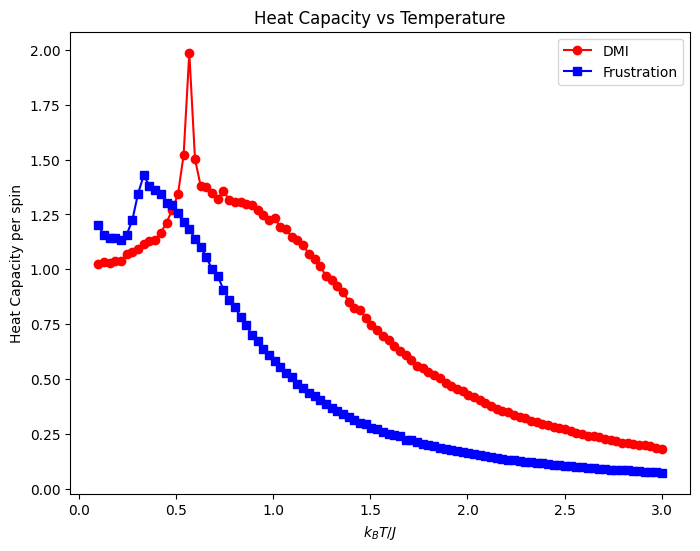

In [63]:
plt.figure(figsize=(8, 6))
plt.plot(T, c_vs_t_dmi, marker="o", color="red", label="DMI") 
plt.plot(T, c_vs_t_frustration, marker="s", color="blue", label="Frustration")
plt.xlabel(r"$k_B T/J$")
plt.ylabel("Heat Capacity per spin")
plt.title("Heat Capacity vs Temperature")
plt.legend()
plt.show()

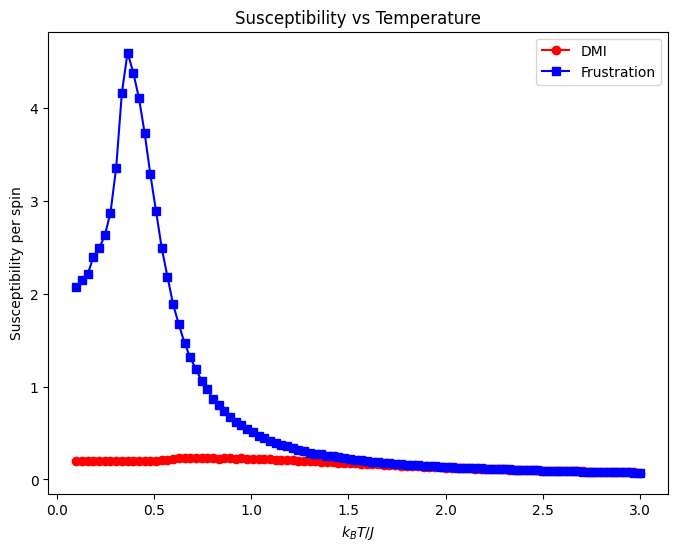

In [64]:
plt.figure(figsize=(8, 6))
plt.plot(T, kai_vs_t_dmi, marker="o", color="red", label="DMI")
plt.plot(T, kai_vs_t_frustration, marker="s", color="blue", label="Frustration")
plt.xlabel(r"$k_B T/J$")
plt.ylabel("Susceptibility per spin")
plt.title("Susceptibility vs Temperature")
plt.legend()
plt.show()

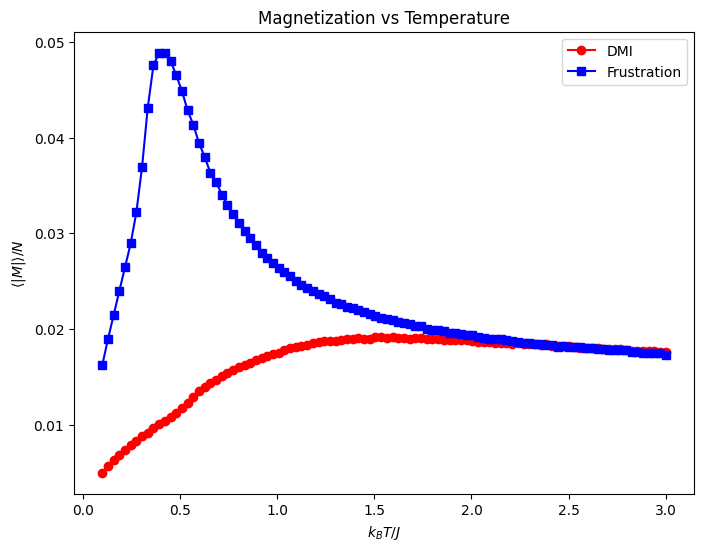

In [65]:
plt.figure(figsize=(8, 6))
plt.plot(T, m_vs_t_dmi, marker="o", color="red", label="DMI")
plt.plot(T, m_vs_t_frustration, marker="s", color="blue", label="Frustration")
plt.xlabel(r"$k_B T/J$")
plt.ylabel(r"$\langle |M| \rangle/N$")
plt.title("Magnetization vs Temperature")
plt.legend()
plt.show()

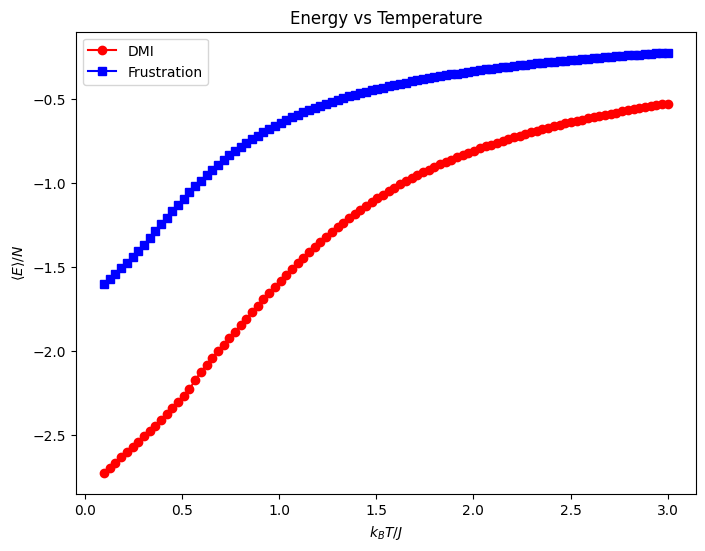

In [66]:
plt.figure(figsize=(8, 6))
plt.plot(T, e_vs_t_dmi, marker="o", color="red", label="DMI")
plt.plot(T, e_vs_t_frustration, marker="s", color="blue", label="Frustration")
plt.xlabel(r"$k_B T/J$")
plt.ylabel(r"$\langle E \rangle/N$")
plt.title("Energy vs Temperature")
plt.legend()
plt.show()

In [68]:
df = pd.DataFrame({
    "T": T,
    "C_DMI": c_vs_t_dmi,
    "Kai_DMI": kai_vs_t_dmi,
    "M_DMI": m_vs_t_dmi,
    "E_DMI": e_vs_t_dmi,
    "R_DMI": r_vs_t_dmi,
    "Sigma_DMI": sigma_vs_t_dmi,
    "C_Frustration": c_vs_t_frustration,
    "Kai_Frustration": kai_vs_t_frustration,
    "M_Frustration": m_vs_t_frustration,
    "E_Frustration": e_vs_t_frustration,
    "R_Frustration": r_vs_t_frustration,
    "Sigma_Frustration": sigma_vs_t_frustration
})

df.to_csv("simulation_results.csv", index=False)